In [5]:
'''
title: "Ex-06: Classifying Spam Emails"
  author: Yohannes Abebe Nigusie
  format:
    html:
      embed-resources: true
  toc: true
  jupyter: python3
'''

'\ntitle: "Ex-06: Classifying Spam Emails"\n  author: Yohannes Abebe Nigusie\n  format:\n    html:\n      embed-resources: true\n  toc: true\n  jupyter: python3\n'

In [6]:
%pip install pandas numpy scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# Load the dataset
spam = pd.read_csv("data/spam.csv")

In [6]:
# Display the first five rows
spam.head()

,crl.tot,dollar,bang,money,n000,make,yesno
0,278,0.000,0.778,0.00,0.00,0.00,y
1,1028,0.180,0.372,0.43,0.43,0.21,y
2,2259,0.184,0.276,0.06,1.16,0.06,y
3,191,0.000,0.137,0.00,0.00,0.00,y
4,191,0.000,0.135,0.00,0.00,0.00,y


In [7]:
# Check the dimensions of the dataset
print(spam.shape)

(4601, 7)


In [8]:
# Check column names and data types
spam.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4601 entries, 0 to 4600
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crl.tot  4601 non-null   int64  
 1   dollar   4601 non-null   float64
 2   bang     4601 non-null   float64
 3   money    4601 non-null   float64
 4   n000     4601 non-null   float64
 5   make     4601 non-null   float64
 6   yesno    4601 non-null   object 
dtypes: float64(5), int64(1), object(1)
memory usage: 251.7+ KB


In [9]:
# Identify categorical columns
categorical_columns = spam.select_dtypes(
    include=['object', 'category']
).columns.tolist()

# Create label encoders
label_encoders = {
    col: LabelEncoder() for col in categorical_columns
}

# Encode categorical columns
for col in categorical_columns:
    spam[col] = label_encoders[col].fit_transform(spam[col])
    
print(spam['yesno'].unique())
print(spam.head())

[1 0]
   crl.tot  dollar   bang  money  n000  make  yesno
0      278   0.000  0.778   0.00  0.00  0.00      1
1     1028   0.180  0.372   0.43  0.43  0.21      1
2     2259   0.184  0.276   0.06  1.16  0.06      1
3      191   0.000  0.137   0.00  0.00  0.00      1
4      191   0.000  0.135   0.00  0.00  0.00      1


In [10]:
# Define features and target
X = spam.drop('yesno', axis=1)
y = spam['yesno']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (4601, 6)
Target shape: (4601,)


In [11]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (3680, 6)
Testing features: (921, 6)
Training target: (3680,)
Testing target: (921,)


In [12]:
# Apply PCA
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("Original training shape:", X_train.shape)
print("PCA training shape:", X_train_pca.shape)

print("Original testing shape:", X_test.shape)
print("PCA testing shape:", X_test_pca.shape)

Original training shape: (3680, 6)
PCA training shape: (3680, 2)
Original testing shape: (921, 6)
PCA testing shape: (921, 2)


In [13]:
from sklearn.tree import DecisionTreeClassifier
dt_classifier = DecisionTreeClassifier(
    random_state=42
)
# Train the Decision Tree
dt_classifier.fit(X_train_pca, y_train)

DecisionTreeClassifier(random_state=42)

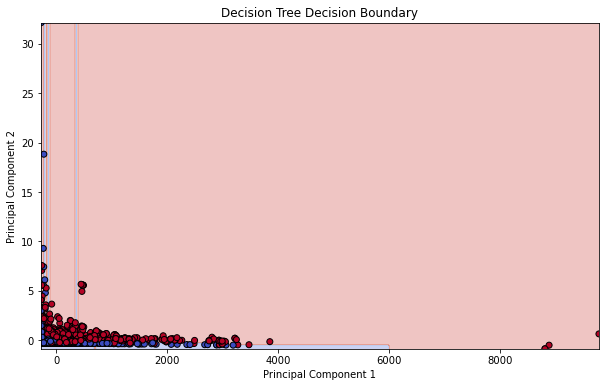

In [14]:
def decisionplot(model, X, y):

    # Extract the two principal components
    x1 = X.iloc[:, 0]
    x2 = X.iloc[:, 1]

    # Create a grid of points
    xx, yy = np.meshgrid(
        np.linspace(x1.min(), x1.max(), 300),
        np.linspace(x2.min(), x2.max(), 300)
    )

    # Predict the class for every point
    Z = model.predict(
        np.c_[xx.ravel(), yy.ravel()]
    )

    # Reshape predictions into a grid
    Z = Z.reshape(xx.shape)

    # Draw the decision regions
    plt.figure(figsize=(10, 6))

    plt.contourf(
        xx, yy, Z,
        alpha=0.3,
        cmap='coolwarm'
    )

    # Plot the actual observations
    plt.scatter(
        x1, x2,
        c=y,
        cmap='coolwarm',
        edgecolors='black'
    )

    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.title('Decision Tree Decision Boundary')
    plt.show()
    

# Convert PCA data into a DataFrame
X_train_pca_df = pd.DataFrame(
    X_train_pca,
    columns=['PC1', 'PC2']
)

# Visualize the decision boundary
decisionplot(
    dt_classifier,
    X_train_pca_df,
    y_train
)    

In [15]:
# Predict using the testing data
predictions = dt_classifier.predict(X_test_pca)

# Display the first 10 predictions
print(predictions[:10])

# Compare predicted and actual values
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': predictions
})

print(comparison.head(10))

[0 0 0 0 0 0 0 0 0 0]
   Actual  Predicted
0       0          0
1       0          0
2       0          0
3       1          0
4       0          0
5       1          0
6       0          0
7       0          0
8       0          0
9       0          0


In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve
)

# Calculate evaluation metrics

accuracy = accuracy_score(y_test, predictions)

precision = precision_score(
    y_test, predictions, average='weighted'
)

recall = recall_score(
    y_test, predictions, average='weighted'
)

f1 = f1_score(
    y_test, predictions, average='weighted'
)

# Display results
print(f"Accuracy: {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")

Accuracy: 0.81
Precision: 0.81
Recall: 0.81
F1 Score: 0.81


AUC for class 0: 0.7691
AUC for class 1: 0.7691


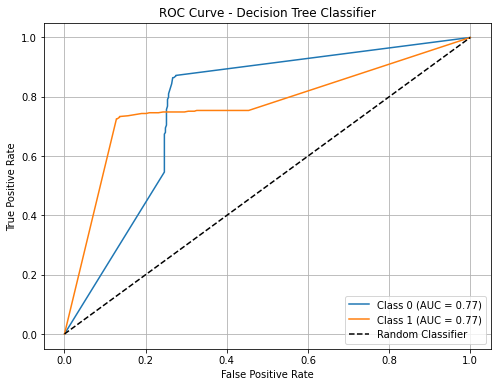

In [17]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import auc

# Binarize the target labels
y_test_bin = label_binarize(y_test, classes=[0, 1])

# Create binary indicators for both classes
y_test_multi = np.column_stack((
    1 - y_test_bin.ravel(),
    y_test_bin.ravel()
))

# Get prediction probabilities
y_score = dt_classifier.predict_proba(X_test_pca)

# Calculate ROC curve and AUC for each class
roc_auc = {}

for i in range(2):
    fpr, tpr, thresholds = roc_curve(
        y_test_multi[:, i],
        y_score[:, i]
    )

    roc_auc[i] = auc(fpr, tpr)

    print(f"AUC for class {i}: {roc_auc[i]:.4f}")
    
plt.figure(figsize=(8, 6))

for i in range(2):
    fpr, tpr, thresholds = roc_curve(
        y_test_multi[:, i],
        y_score[:, i]
    )

    plt.plot(
        fpr,
        tpr,
        label=f'Class {i} (AUC = {roc_auc[i]:.2f})'
    )

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    'k--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Decision Tree Classifier')
plt.legend()
plt.grid()
plt.show()

In [18]:
# Summary of the data
results = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score',
        'AUC - Not Spam',
        'AUC - Spam'
    ],
    'Score': [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc[0],
        roc_auc[1]
    ]
})

print(results)

           Metric     Score
0        Accuracy  0.808903
1       Precision  0.808574
2          Recall  0.808903
3        F1 Score  0.807311
4  AUC - Not Spam  0.769132
5      AUC - Spam  0.769132


In [19]:
from sklearn.metrics import confusion_matrix, classification_report

# Confusion matrix
cm = confusion_matrix(y_test, predictions)

print("Confusion Matrix:")
print(cm)

# Detailed classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    predictions,
    target_names=['Not Spam', 'Spam']
))

Confusion Matrix:
[[462  69]
 [107 283]]

Classification Report:
              precision    recall  f1-score   support

    Not Spam       0.81      0.87      0.84       531
        Spam       0.80      0.73      0.76       390

    accuracy                           0.81       921
   macro avg       0.81      0.80      0.80       921
weighted avg       0.81      0.81      0.81       921

